# giFBA vs. dFBA: Flux Comparison (N_orgs)

Reaction-level comparison of giFBA and dFBA fluxes. Reads the preprocessed `data/N_orgs/fluxes_N_orgs.pkl`, `hyperparams_N_orgs.csv` and `model_names_N_orgs.csv` written by `process_results.py`.

The flux frames hold only reactions active in at least one run, with rows and columns sorted identically for both methods. Hyperparameter-level analysis lives in `4_2_compare_hyperparameters.ipynb`; the fixed two-organism AH_BI experiment has its own flux notebook, `4_3_compare_AH_BI_fluxes.ipynb`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tol_colors as tol
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import benchmark_analysis_utils as bau

## 1. Experiment config

In [2]:
ACTIVE_CONFIG_NAME = "N_orgs"

config = bau.PRESETS[ACTIVE_CONFIG_NAME]
DATA_DIR = Path("data") / config.name
FIG_DIR = Path("../../figures/real_model_figs/dfba_benchmark")
FIG_DIR.mkdir(parents=True, exist_ok=True)

missing = [
    p for p in (
        DATA_DIR / f"hyperparams_{config.name}.csv",
        DATA_DIR / f"model_names_{config.name}.csv",
        DATA_DIR / f"fluxes_{config.name}.pkl",
    )
    if not p.exists()
]
if missing:
    raise FileNotFoundError(
        f"Missing processed files {[str(p) for p in missing]}; "
        f"run `python process_results.py --config {config.name}` first."
    )
config

ExperimentConfig(name='N_orgs', results_dir='Benchmark_N_orgs', max_time_s=86400, binning={'vmax': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'km': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.1f}', zero_floor=False), 'early_stop_window': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'early_stop_tol': BinSpec(spread='log', bins=3, min=None, max=None, fmt_bins='{:.1e}', zero_floor=False), 'rel_abund': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.2f}', zero_floor=False), 'y0_factor': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True), 'y0_offset': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True)})

## 2. Load processed results

In [3]:
df = pd.read_csv(DATA_DIR / f"hyperparams_{config.name}.csv", index_col=0)
for col in bau.present(["rel_abund_list", "media"], df):
    df[col] = df[col].map(json.loads)

model_names = pd.read_csv(DATA_DIR / f"model_names_{config.name}.csv", index_col=0).iloc[:, 0].map(json.loads)

# Per-run equivalence metrics written by process_results.py (see
# bau.calc_equivalence_metrics for the raw sums).
EQ_COLS = [
    "Abs_Diff_Sum", "Sum_Rel_Error", "N_nonzero_rxns", "N_rxns", "Sum_Abs_Flux",
    "gifba_abs_flux_sum", "dfba_abs_flux_sum",
    "MAE", "RPE",
]
eq_df = df[EQ_COLS].copy()

print(f"Loaded {len(df)} runs from {DATA_DIR}")
df.head()

Loaded 430 runs from data/N_orgs


,N_models,rel_abund,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,early_stop_window,early_stop_tol,...,Abs_Diff_Sum,Sum_Rel_Error,N_nonzero_rxns,N_rxns,Sum_Abs_Flux,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE,RPE,RPE_abs
run_id,,,,,,,,,,,,,,,,,,,,,
5906512_1,4,0.113436,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",7489,6790,19.179103,0.120450,BDF,20,1.000000e-07,...,13.906465,17.409310,133,7489,307.817473,153.894936,153.922536,0.001857,0.002325,0.002325
5912065_1,9,0.055533,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",15760,14262,11.768120,0.432876,BDF,20,1.000000e-07,...,35.322745,2.583354,4120,15760,269.127516,128.444733,140.682783,0.002241,0.000164,0.000164
5912065_10,9,0.050241,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",17718,15637,55.908102,0.792483,RK45,20,1.000000e-07,...,13.203588,117.162417,2297,17718,259.226305,130.900421,128.325884,0.000745,0.006613,0.006613
5912065_100,8,0.058220,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",13613,12040,22.051307,0.178865,BDF,20,1.000000e-07,...,12.179044,-58.555883,581,13613,221.611803,112.108170,109.503634,0.000895,-0.004301,0.004301
5912065_101,9,0.050154,"{'EX_etoh(e)': -234.434015507376, 'EX_h2o(e)':...",11778,10806,20.092330,0.911163,RK45,20,1.000000e-07,...,61.380406,-36.528021,3934,11778,332.074038,155.931438,176.142600,0.005211,-0.003101,0.003101


In [4]:
fluxes = pd.read_pickle(DATA_DIR / f"fluxes_{config.name}.pkl")
gifba_fluxes_df = fluxes["gifba"]
dfba_fluxes_df = fluxes["dfba"]
flux_hist_counts = fluxes["flux_hist_counts"]
flux_hist_bin_edges = fluxes["flux_hist_bin_edges"]

assert gifba_fluxes_df.index.equals(df.index) and dfba_fluxes_df.index.equals(df.index)
assert gifba_fluxes_df.columns.equals(dfba_fluxes_df.columns)

print(f"giFBA fluxes: {gifba_fluxes_df.shape}")
print(f" dFBA fluxes: {dfba_fluxes_df.shape}")
print("giFBA: \n", gifba_fluxes_df.iloc[:5, :5])
print("dFBA: \n", dfba_fluxes_df.iloc[:5, :5])

giFBA fluxes: (430, 27505)
 dFBA fluxes: (430, 27505)
giFBA: 
              12DGR180tex___0  12DGR180tex___1  12DGR180tex___2  \
5906512_1                0.0              0.0              0.0   
5912065_1                0.0              0.0              0.0   
5912065_10               0.0              0.0              0.0   
5912065_100              0.0              0.0              0.0   
5912065_101              0.0              0.0              0.0   

             12DGR180tex___3  12DGR180tex___4  
5906512_1                0.0              0.0  
5912065_1                0.0              0.0  
5912065_10               0.0              0.0  
5912065_100              0.0              0.0  
5912065_101              0.0              0.0  
dFBA: 
              12DGR180tex___0  12DGR180tex___1  12DGR180tex___2  \
5906512_1                0.0              0.0              0.0   
5912065_1                0.0              0.0              0.0   
5912065_10               0.0              0.0 

## 3. Flux magnitude histogram

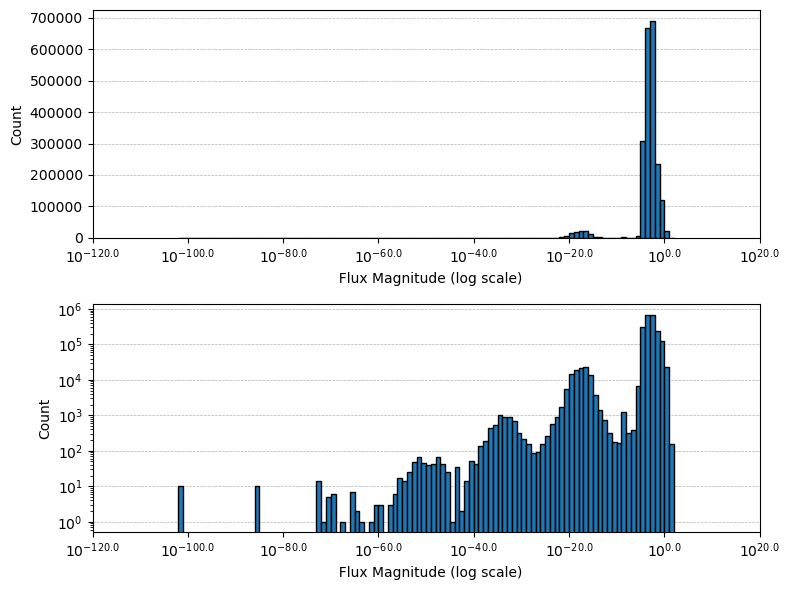

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(8, 6))
for ax, is_counts_log_scale in zip(axs, [False, True]):
    ax.bar(flux_hist_bin_edges[:-1], flux_hist_counts, width=1, align="edge", edgecolor="black", zorder=3)
    ax.set_xlabel("  Flux Magnitude (log scale)")
    if is_counts_log_scale:
        ax.set_yscale("log")
    ax.set_ylabel("Count")
    x_ticks = ax.get_xticks()
    ax.set_xticks(x_ticks)
    ax.set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
    ax.grid(axis="y", linestyle="--", linewidth=0.5, zorder=0)

plt.tight_layout()
plt.savefig(FIG_DIR / f"flux_magnitude_histogram_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 4. Filter out zero-growth and single-organism runs

In [6]:
times = df["dfba_termination_t"]
print(sum(times == 100), "out of", len(times), "simulations terminated without convergence")

zero_error_mask = (eq_df["MAE"] == 0) & (eq_df["RPE"] == 0)
print(sum(zero_error_mask), "out of", len(zero_error_mask), "simulations have 0 error")
zero_growth_mask = eq_df["Sum_Abs_Flux"] == 0
print(sum(zero_growth_mask), "out of", len(zero_growth_mask), "simulations have 0 growth")
singleton_mask = df["N_models"] == 1
print(sum(singleton_mask), "out of", len(singleton_mask), "simulations have N_models == 1")

filter_mask = ~zero_growth_mask & ~singleton_mask
eq_df_filtered = eq_df[filter_mask]

349 out of 430 simulations terminated without convergence
12 out of 430 simulations have 0 error
7 out of 430 simulations have 0 growth
47 out of 430 simulations have N_models == 1


## 5. 3D efficiency scatter + best/worst-example flux comparison

In [7]:
df_filtered = df[filter_mask]

X_data = df_filtered["dfba_pfba_calls"].values
X_lab = "# dFBA pFBA Calls"
X_scale = "log"

Y_data = df_filtered["gifba_pfba_calls"].values
Y_lab = "# giFBA pFBA Calls"
Y_scale = "log"
yvar = "log-pfba-ratio"

Z_data = eq_df_filtered["MAE"].values
Z_lab = "MAE"
Z_scale = "linear"

fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"type": "scene"}, {"type": "xy"}, {"type": "xy"}]],
    column_widths=[0.42, 0.29, 0.29],
    horizontal_spacing=0.06,
    subplot_titles=(
        "",
        "Best MAE Example (MAE = {:.2e})".format(eq_df_filtered["MAE"].min()),
        "Worst MAE Example (MAE = {:.2e})".format(eq_df_filtered["MAE"].max()),
    ),
)

for solver, color in bau.SOLVER_COLORS.items():
    solver_mask = (df_filtered["solver_method"] == solver).to_numpy()
    fig.add_trace(
        go.Scatter3d(
            x=X_data[solver_mask], y=Y_data[solver_mask], z=Z_data[solver_mask],
            mode="markers", name=solver,
            marker=dict(size=3, color=color, opacity=0.8),
            legend="legend",
        ),
        row=1, col=1,
    )

best_idx = eq_df_filtered["MAE"].idxmin()
worst_idx = eq_df_filtered["MAE"].idxmax()

gifba_best = gifba_fluxes_df.loc[best_idx]
dfba_best = dfba_fluxes_df.loc[best_idx].reindex(gifba_best.index)
best_color_map = bau.build_org_color_map(gifba_best.index.map(bau.get_org_index), plt.cm.Accent)
best_bounds = bau.add_flux_traces(fig, gifba_best, dfba_best, model_names.get(best_idx), best_color_map, "legend2", 2)

gifba_worst = gifba_fluxes_df.loc[worst_idx]
dfba_worst = dfba_fluxes_df.loc[worst_idx].reindex(gifba_worst.index)
worst_color_map = bau.build_org_color_map(gifba_worst.index.map(bau.get_org_index), plt.cm.Accent)
worst_bounds = bau.add_flux_traces(fig, gifba_worst, dfba_worst, model_names.get(worst_idx), worst_color_map, "legend3", 3)

# Plotly's default eye is ~1.25; anything much larger shrinks the cube inside its domain.
camera_zoom = 1.35
axis_style = dict(
    showgrid=True, zeroline=True, showticklabels=True,
    exponentformat="power", showexponent="all",
    tickfont=dict(size=10), title_font=dict(size=12), nticks=5,
)
fig.update_layout(
    scene=dict(
        xaxis_title=X_lab,
        yaxis_title=Y_lab,
        zaxis_title=Z_lab,
        xaxis=dict(type=X_scale, **axis_style),
        yaxis=dict(type=Y_scale, **axis_style),
        zaxis=dict(type=Z_scale, **axis_style),
        aspectmode="cube",
        camera=dict(eye=dict(x=camera_zoom, y=camera_zoom, z=camera_zoom * 0.8)),
    ),
    height=650,
    width=1500,
    margin=dict(l=10, r=10, t=50, b=140),
    showlegend=True,
    template="simple_white",
    legend=dict(
        title=dict(text="dFBA Solver"),
        orientation="v", x=0.185, y=-0.12, xanchor="center", yanchor="top",
    ),
    legend2=dict(
        title=dict(text="Organism ID"),
        orientation="v", x=0.56, y=-0.12, xanchor="center", yanchor="top",
    ),
    legend3=dict(
        title=dict(text="Organism ID"),
        orientation="v", x=0.87, y=-0.12, xanchor="center", yanchor="top",
    )
)

fig.show()
fig.write_html(FIG_DIR / f"3d_scatter_efficiency_{yvar}_mae_{config.name}.html")

## 6. Hyperparameters of the best/worst runs

In [8]:
param_cols = bau.present(
    ["vmax", "km", "rel_abund", "y0_factor", "y0_offset", "solver_method",
     "early_stop_window", "early_stop_tol", "gifba_iter_converged",
     "gifba_periodicity", "dfba_pfba_calls", "gifba_pfba_calls", "dfba_solve_time", "gifba_solve_time",
     "log10_time_ratio", "log10_pfba_call_ratio", "MAE", "RPE"],
    df,
)
print(pd.DataFrame({
    "Best Run": df.loc[best_idx, param_cols],
    "Worst Run": df.loc[worst_idx, param_cols],
}).to_string() )


                         Best Run   Worst Run
vmax                    24.770764    11.49757
km                       0.642807    0.890215
rel_abund                0.169825     0.05301
solver_method                 BDF         BDF
early_stop_window              20          20
early_stop_tol                0.0         0.0
gifba_iter_converged          3.0         4.0
gifba_periodicity             1.0         1.0
dfba_pfba_calls              2320        5148
gifba_pfba_calls             24.0       100.0
dfba_solve_time        173.122677  311.337076
gifba_solve_time        24.025289   31.672565
log10_time_ratio         0.857685    0.992548
log10_pfba_call_ratio    1.985277    1.711639
MAE                      0.000008    0.050104
RPE                      0.020537    0.000668


## 7. Per-reaction absolute difference for a single run

In [9]:
RUN_ID = best_idx

abs_diff = (gifba_fluxes_df.loc[RUN_ID] - dfba_fluxes_df.loc[RUN_ID]).abs()
factor = (gifba_fluxes_df.loc[RUN_ID] / dfba_fluxes_df.loc[RUN_ID]).astype("float64")
run_comparison = pd.DataFrame({
    "gifba": gifba_fluxes_df.loc[RUN_ID],
    "dfba": dfba_fluxes_df.loc[RUN_ID],
    "abs_diff": abs_diff,
    "factor": factor
})
run_comparison["organism"] = [
    bau.get_org_label(model_names.get(RUN_ID), bau.get_org_index(c)) for c in run_comparison.index
]

print(f"Run {RUN_ID}: MAE = {df.loc[RUN_ID, 'MAE']:.3e}")
run_comparison.sort_values("abs_diff", ascending=False).head(20)

Run 5912065_72: MAE = 8.323e-06


,gifba,dfba,abs_diff,factor,organism
GAPD___1,0.372386,0.367034,0.005352,1.014581,Salmonella_enterica_subsp_enterica_serovar_Ent...
GAPD_NADP___1,0.123944,0.129296,0.005352,0.958608,Salmonella_enterica_subsp_enterica_serovar_Ent...
IPDPS___1,0.005352,0.0,0.005352,inf,Salmonella_enterica_subsp_enterica_serovar_Ent...
IPDPS2___1,0.0,0.005352,0.005352,0.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...
FRD2___1,0.000726,0.0,0.000726,inf,Salmonella_enterica_subsp_enterica_serovar_Ent...
DHORD5___1,0.000726,0.0,0.000726,inf,Salmonella_enterica_subsp_enterica_serovar_Ent...
DHORD2___1,0.0,0.000726,0.000726,0.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...
FRD7___1,0.007771,0.008497,0.000726,0.914538,Salmonella_enterica_subsp_enterica_serovar_Ent...
L_LACt2rpp___1,-0.32584,-0.32584,0.0,1.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...
LDH_L___1,-0.32584,-0.32584,0.0,1.000000,Salmonella_enterica_subsp_enterica_serovar_Ent...


## 8. Interactive run explorer

Click any run in the left panel to plot its giFBA vs. dFBA fluxes in the middle panel and list its hyperparameters in the table on the right. The circled point marks the run currently shown, starting with the best-MAE run. Organism legend entries follow the selected run's community. The figure is also saved as a standalone HTML file in `FIG_DIR`.

In [ ]:
import base64
import gzip

from IPython.display import HTML, display
from matplotlib.colors import to_hex

# Click-to-inspect, as in 4_3: clicking a run in the left panel redraws the middle panel with
# that run's giFBA vs. dFBA fluxes and the right-hand table with its hyperparameters. Unlike
# AH_BI, giFBA fluxes and the organism set change from run to run, so both vectors are embedded
# for every kept run (~1M points). Plain JSON would be ~30 MB, so the active fluxes go in as one
# gzipped binary blob that the browser inflates once with DecompressionStream:
#   [float32 giFBA | float32 dFBA | uint16 column index | utf-8 column names, "\n"-joined]
# Float32 mantissas are rounded to 12 bits (~4 significant digits), which is what the hover shows
# and lets gzip compress the values.
MAX_ORGS = int(df_filtered["N_models"].max())
ORG_SLOT_COLORS = [to_hex(c) for c in plt.cm.tab10.colors][:MAX_ORGS]

col_names = gifba_fluxes_df.columns
col_org = col_names.map(bau.get_org_index).astype(int).to_numpy()
assert len(col_names) < 2**16, "column index no longer fits in uint16"

g_all = gifba_fluxes_df.loc[df_filtered.index].to_numpy(dtype="float64")
d_all = dfba_fluxes_df.loc[df_filtered.index].to_numpy(dtype="float64")
n_models = df_filtered["N_models"].to_numpy()
active = ((g_all != 0) | (d_all != 0)) & (col_org[None, :] < n_models[:, None])
run_rows, col_idx = np.nonzero(active)
offsets = np.concatenate([[0], np.cumsum(active.sum(axis=1))])


def round_mantissa(x: np.ndarray, keep_bits: int = 12) -> np.ndarray:
    """Rounds float32 values to `keep_bits` mantissa bits so the blob compresses."""
    drop = 23 - keep_bits
    u = x.astype("float32").view(np.uint32)
    u = (u + np.uint32(1 << (drop - 1))) & np.uint32(~((1 << drop) - 1) & 0xFFFFFFFF)
    return u.view(np.float32)


blob = b"".join([
    round_mantissa(g_all[run_rows, col_idx]).tobytes(),
    round_mantissa(d_all[run_rows, col_idx]).tobytes(),
    col_idx.astype("<u2").tobytes(),
    "\n".join(col_names).encode(),
])
blob_b64 = base64.b64encode(gzip.compress(blob, compresslevel=9, mtime=0)).decode()

TABLE_COLS = bau.present(
    ["N_models", "rel_abund_list", "solver_method", "vmax", "km", "y0_factor", "y0_offset",
     "early_stop_window", "early_stop_tol", "dfba_status", "dfba_termination_t",
     "dfba_pfba_calls", "gifba_pfba_calls", "dfba_solve_time", "gifba_solve_time",
     "log10_time_ratio", "log10_pfba_call_ratio", "gifba_iter_converged", "gifba_periodicity",
     "dfba_abs_flux_sum", "gifba_abs_flux_sum", "MAE", "RPE"],
    df,
)


def fmt_value(v: object) -> str:
    """Formats one hyperparameter value for the table."""
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(fmt_value(x) for x in v) + "]"
    if isinstance(v, (bool, np.bool_)) or not isinstance(v, (int, float, np.number)):
        return str(v)
    if isinstance(v, (int, np.integer)) or float(v).is_integer():
        return f"{int(v):,d}"
    return f"{v:.4g}"


call_ratio = df_filtered["dfba_pfba_calls"] / df_filtered["gifba_pfba_calls"]
run_ids = df_filtered.index.tolist()
run_meta = {
    run_id: {
        "i": i,
        "orgs": [bau.get_org_label(model_names.get(run_id), str(k)) for k in range(int(n_models[i]))],
        "title": f"Run {run_id} (N = {n_models[i]}, MAE = {df.loc[run_id, 'MAE']:.2e}, "
                 f"{df.loc[run_id, 'solver_method']}, vmax = {df.loc[run_id, 'vmax']:.3g})",
        "mae": float(df.loc[run_id, "MAE"]),
        "ratio": float(call_ratio[run_id]),
        "table": [fmt_value(df.loc[run_id, c]) for c in TABLE_COLS],
    }
    for i, run_id in enumerate(run_ids)
}

ifig = make_subplots(
    rows=1, cols=3, column_widths=[0.38, 0.38, 0.24], horizontal_spacing=0.07,
    specs=[[{}, {}, {"type": "table"}]],
    subplot_titles=("dFBA/giFBA cost vs. error (click a point)", run_meta[best_idx]["title"], "Hyperparameters"),
)

solver_traces = []
for solver, color in bau.SOLVER_COLORS.items():
    runs = df_filtered[df_filtered["solver_method"] == solver]
    solver_traces.append(len(ifig.data))
    ifig.add_trace(
        go.Scatter(
            x=runs["MAE"], y=call_ratio[runs.index], mode="markers", name=solver,
            marker=dict(size=6, color=color, opacity=0.7),
            customdata=np.column_stack([runs.index, runs["N_models"]]),
            hovertemplate="run %{customdata[0]} (N = %{customdata[1]})<br>MAE: %{x:.3g}"
                          "<br>dFBA/giFBA pFBA calls: %{y:.3g}<extra>" + solver + "</extra>",
            legend="legend",
        ),
        row=1, col=1,
    )
ifig.add_hline(y=1, line_dash="dash", line_color="black", line_width=1.2, row=1, col=1)
ifig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", line=dict(color="black", dash="dash"),
                          name="equal pFBA calls", legend="legend"), row=1, col=1)

selected_trace = len(ifig.data)
ifig.add_trace(
    go.Scatter(
        x=[run_meta[best_idx]["mae"]], y=[run_meta[best_idx]["ratio"]], mode="markers",
        marker=dict(size=14, color="rgba(0,0,0,0)", line=dict(color="black", width=2)),
        hoverinfo="skip", showlegend=False,
    ),
    row=1, col=1,
)
ifig.update_xaxes(type="log", title_text="MAE (giFBA vs. dFBA)", showgrid=True,
                  exponentformat="power", showexponent="all", row=1, col=1)
ifig.update_yaxes(type="log", title_text="dFBA / giFBA pFBA calls", showgrid=True,
                  exponentformat="power", showexponent="all", row=1, col=1)

# One trace per organism slot (index 0..MAX_ORGS-1); the JS fills in each run's points and
# species names and hides the slots that run doesn't use. Points are empty until the blob loads.
org_traces = []
for k, color in enumerate(ORG_SLOT_COLORS):
    org_traces.append(len(ifig.data))
    ifig.add_trace(
        go.Scatter(
            x=[], y=[], mode="markers", name=f"org {k}",
            marker=dict(size=6, color=color, opacity=0.7),
            hovertemplate="%{customdata}<br>giFBA: %{x:.4g}<br>dFBA: %{y:.4g}<extra>%{fullData.name}</extra>",
            legend="legend2",
        ),
        row=1, col=2,
    )
big = 10 * float(max(np.abs(g_all).max(), np.abs(d_all).max()))
ifig.add_trace(
    go.Scatter(x=[-big, big], y=[-big, big], mode="lines", line=dict(color="black", dash="dash", width=1),
               opacity=0.6, name="y = x", hoverinfo="skip", legend="legend2"),
    row=1, col=2,
)
ifig.add_hline(y=0, line_color="black", line_width=0.8, opacity=0.2, row=1, col=2)
ifig.add_vline(x=0, line_color="black", line_width=0.8, opacity=0.2, row=1, col=2)
ifig.update_xaxes(title_text="giFBA flux", showgrid=True, row=1, col=2)
ifig.update_yaxes(title_text="dFBA flux", showgrid=True, row=1, col=2)

table_trace = len(ifig.data)
ifig.add_trace(
    go.Table(
        columnwidth=[0.5, 0.5],
        header=dict(values=["<b>parameter</b>", "<b>value</b>"], align="left", fill_color="#e8e8e8"),
        cells=dict(values=[TABLE_COLS, run_meta[best_idx]["table"]], align="left", height=22),
    ),
    row=1, col=3,
)

ifig.update_layout(
    template="simple_white",
    height=700, width=1650,
    margin=dict(b=200),
    legend=dict(title=dict(text="dFBA solver"), orientation="h", x=0.19, y=-0.15, xanchor="center", yanchor="top"),
    legend2=dict(title=dict(text="Organism"), orientation="v", x=0.6, y=-0.15, xanchor="center", yanchor="top"),
)

click_js = """
const gd = document.getElementById('{plot_id}');
const RUNS = %(runs)s;
const OFFSETS = %(offsets)s;
const SOLVER_TRACES = %(solver_traces)s;
const ORG_TRACES = %(org_traces)s;
const SELECTED = %(selected)d;
const TABLE = %(table)d;
const TABLE_COLS = %(table_cols)s;
const N_PTS = OFFSETS[OFFSETS.length - 1];
let G, D, COL, RXN, ORG;

async function loadFluxes() {
    const bytes = Uint8Array.from(atob('%(blob)s'), c => c.charCodeAt(0));
    const stream = new Blob([bytes]).stream().pipeThrough(new DecompressionStream('gzip'));
    const buf = await new Response(stream).arrayBuffer();
    G = new Float32Array(buf, 0, N_PTS);
    D = new Float32Array(buf, 4 * N_PTS, N_PTS);
    COL = new Uint16Array(buf, 8 * N_PTS, N_PTS);
    const names = new TextDecoder().decode(new Uint8Array(buf, 10 * N_PTS)).split('\\n');
    RXN = names.map(n => n.slice(0, n.lastIndexOf('___')));
    ORG = names.map(n => +n.slice(n.lastIndexOf('___') + 3));
}

function showRun(runId) {
    const run = RUNS[runId];
    if (!run) return;
    const xs = ORG_TRACES.map(() => []), ys = ORG_TRACES.map(() => []), names = ORG_TRACES.map(() => []);
    let lo = Infinity, hi = -Infinity;
    for (let p = OFFSETS[run.i]; p < OFFSETS[run.i + 1]; p++) {
        const k = ORG[COL[p]];
        xs[k].push(G[p]); ys[k].push(D[p]); names[k].push(RXN[COL[p]]);
        lo = Math.min(lo, G[p], D[p]); hi = Math.max(hi, G[p], D[p]);
    }
    Plotly.restyle(gd, {
        x: xs, y: ys, customdata: names,
        name: ORG_TRACES.map((_, k) => run.orgs[k] || ''),
        visible: ORG_TRACES.map((_, k) => k < run.orgs.length),
    }, ORG_TRACES);
    Plotly.restyle(gd, {x: [[run.mae]], y: [[run.ratio]]}, [SELECTED]);
    Plotly.restyle(gd, {'cells.values': [[TABLE_COLS, run.table]]}, [TABLE]);
    const pad = 0.05 * (hi - lo || 1);
    Plotly.relayout(gd, {
        'annotations[1].text': run.title,
        'xaxis2.range': [lo - pad, hi + pad], 'yaxis2.range': [lo - pad, hi + pad],
    });
}

gd.on('plotly_click', ev => {
    const pt = ev.points[0];
    if (G && SOLVER_TRACES.includes(pt.curveNumber)) showRun(pt.customdata[0]);
});
loadFluxes().then(() => showRun(%(initial)s));
""" % dict(
    runs=json.dumps(run_meta),
    offsets=json.dumps(offsets.tolist()),
    solver_traces=json.dumps(solver_traces),
    org_traces=json.dumps(org_traces),
    selected=selected_trace,
    table=table_trace,
    table_cols=json.dumps(TABLE_COLS),
    blob=blob_b64,
    initial=json.dumps(best_idx),
)

ifig.write_html(f"interactive_mae_flux_explorer_{config.name}.html",
                include_plotlyjs="cdn", post_script=click_js)
display(HTML(ifig.to_html(include_plotlyjs="cdn", full_html=False, post_script=click_js)))
print(f"{len(run_ids)} runs, {offsets[-1]:,d} flux points, embedded blob {len(blob_b64) / 1e6:.1f} MB")

376 runs, 1,116,676 flux points, embedded blob 6.3 MB
